In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.inspection import DecisionBoundaryDisplay


In [2]:
# load the pharmacy sales dataset
df = pd.read_csv("global_pharmacy_sales_2020_2025_daily_dataset.csv")

# display the first five rows
display(df.head())

# display dataset information
print("dataset shape:", df.shape)
print("columns:", df.columns.tolist())


,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0


dataset shape: (177990, 14)
columns: ['date', 'year', 'month', 'day', 'region', 'country', 'category', 'medicine', 'age_group', 'units_sold', 'unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag']


In [3]:
# classify sales into high and low demand using median sales
median_sales = df["units_sold"].median()

df["demand_class"] = np.where(
    df["units_sold"] >= median_sales,
    "high demand",
    "low demand"
)

# display the number of records in each class
print(df["demand_class"].value_counts())


demand_class
high demand    89217
low demand     88773
Name: count, dtype: int64


In [4]:
# select numerical features for classification
features = [
    "unit_price",
    "stock_level",
    "expiry_days_remaining",
    "month",
    "covid_flag"
]

# use a sample to make svm tuning faster
data = df.sample(n=min(12000, len(df)), random_state=42)

X = data[features]
y = data["demand_class"]

# check for missing values
print(X.isnull().sum())


unit_price               0
stock_level              0
expiry_days_remaining    0
month                    0
covid_flag               0
dtype: int64


In [5]:

# split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("training records:", len(X_train))
print("testing records:", len(X_test))


training records: 9600
testing records: 2400


In [6]:
# scale features before training the svm
# use a pipeline to avoid data leakage during cross-validation
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC())
])

# define kernels and hyperparameters to test
param_grid = [
    {
        "svm__kernel": ["linear"],
        "svm__C": [0.1, 1, 10]
    },
    {
        "svm__kernel": ["rbf"],
        "svm__C": [0.1, 1, 10],
        "svm__gamma": ["scale", 0.01, 0.1]
    },
    {
        "svm__kernel": ["poly"],
        "svm__C": [0.1, 1, 10],
        "svm__degree": [2, 3],
        "svm__gamma": ["scale"]
    }
]


In [7]:
# compare svm kernels using three-fold cross-validation
grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    cv=3,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

# train and find the best svm configuration
grid_search.fit(X_train, y_train)

# display the best parameters and cross-validation score
print("best parameters:", grid_search.best_params_)
print("best cross-validation f1:", grid_search.best_score_)

best_model = grid_search.best_estimator_


Fitting 3 folds for each of 18 candidates, totalling 54 fits
best parameters: {'svm__C': 10, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
best cross-validation f1: 0.8502605142515532


In [8]:
# predict demand classes on unseen test data
y_pred = best_model.predict(X_test)

# calculate test accuracy
accuracy = accuracy_score(y_test, y_pred)
print("test accuracy:", round(accuracy * 100, 2), "%")

# display precision, recall, and f1-score
print(classification_report(y_test, y_pred))


test accuracy: 85.25 %
              precision    recall  f1-score   support

 high demand       0.86      0.84      0.85      1204
  low demand       0.84      0.87      0.85      1196

    accuracy                           0.85      2400
   macro avg       0.85      0.85      0.85      2400
weighted avg       0.85      0.85      0.85      2400



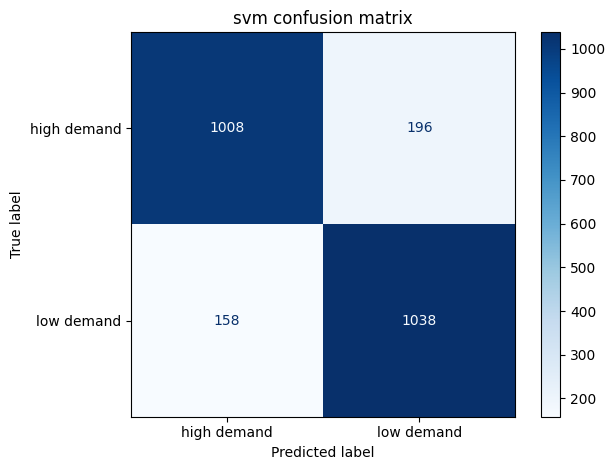

In [9]:
# compare actual and predicted classifications
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues"
)

plt.title("svm confusion matrix")
plt.tight_layout()
plt.show()


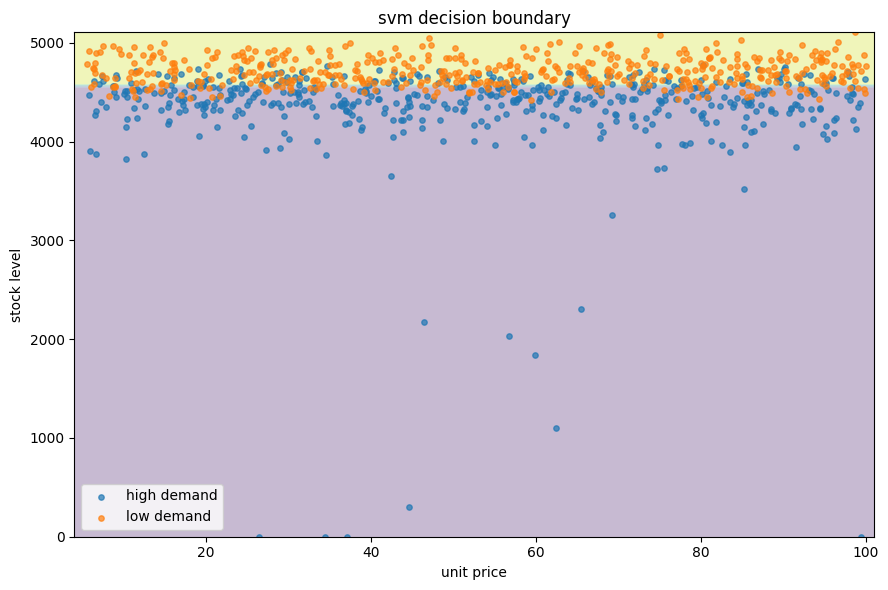

In [10]:

# select two features for decision boundary visualization
X_2d = data[["unit_price", "stock_level"]]
y_2d = data["demand_class"]

# split the two-dimensional dataset
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_2d, y_2d,
    test_size=0.20,
    random_state=42,
    stratify=y_2d
)

# create a model using the best svm parameters
best_params = grid_search.best_params_

boundary_params = {
    key.replace("svm__", ""): value
    for key, value in best_params.items()
    if key.startswith("svm__")
}

boundary_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(**boundary_params))
])

# train the two-feature svm model
boundary_model.fit(X2_train, y2_train)

# plot the decision boundary
fig, ax = plt.subplots(figsize=(9, 6))

DecisionBoundaryDisplay.from_estimator(
    boundary_model,
    X2_train,
    response_method="predict",
    alpha=0.3,
    grid_resolution=100,
    ax=ax
)

# display a sample of training points
sample_points = X2_train.sample(
    n=min(1000, len(X2_train)),
    random_state=42
)

sample_labels = y2_train.loc[sample_points.index]

for label in y2_train.unique():
    mask = sample_labels == label
    ax.scatter(
        sample_points.loc[mask, "unit_price"],
        sample_points.loc[mask, "stock_level"],
        label=label,
        s=15,
        alpha=0.7
    )

ax.set_xlabel("unit price")
ax.set_ylabel("stock level")
ax.set_title("svm decision boundary")
ax.legend()
plt.tight_layout()
plt.show()


In [11]:

# display the cross-validation results for all configurations
results = pd.DataFrame(grid_search.cv_results_)

comparison = results[
    ["param_svm__kernel", "mean_test_score", "std_test_score"]
].copy()

comparison = comparison.sort_values(
    by="mean_test_score",
    ascending=False
)

print(comparison.head(10).to_string(index=False))


param_svm__kernel  mean_test_score  std_test_score
              rbf         0.850261        0.006678
              rbf         0.849302        0.007833
              rbf         0.848290        0.005530
              rbf         0.847453        0.005562
              rbf         0.842680        0.004114
              rbf         0.841950        0.004758
           linear         0.841534        0.004524
           linear         0.841221        0.004620
           linear         0.841219        0.004437
              rbf         0.840485        0.004653


In [12]:

# summarize the svm evaluation
print("svm model evaluation completed")
print("best parameters:", grid_search.best_params_)
print("best cross-validation f1:", round(grid_search.best_score_, 4))
print("test accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("grid search compared linear, rbf, and polynomial kernels.")
print("cross-validation was used to select the best configuration.")
print("the confusion matrix and decision boundary were visualized.")


svm model evaluation completed
best parameters: {'svm__C': 10, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
best cross-validation f1: 0.8503
test accuracy: 0.8525
grid search compared linear, rbf, and polynomial kernels.
cross-validation was used to select the best configuration.
the confusion matrix and decision boundary were visualized.
